# 01 · Getting to know our heart disease data

**DSAI 5101 | Team starter notebook**

Q1: Which factors best predict self-reported heart disease?  
Q2: Which demographic, health and lifestyle variables are most strongly associated with the leading predictors?

This notebook follows the first-contact checks in Lectures 2–3 and Lab 2. It reads the original ZIP, inspects it and audits the proposed target. It does **not** clean the data, fit a model or select predictors. Keep the raw archive unchanged.

## Before running
1. Put this notebook in `notebooks/01_data_understanding.ipynb` in your cloned repository.
2. Keep the archive at `data/raw/heart_2022_with_nans.zip`. No extraction is needed.
3. Install `pandas`, `numpy`, `matplotlib`, `jupyterlab` and `ipykernel` in your Python environment. Open the notebook in JupyterLab or VS Code and choose that environment.
4. Use **Restart Kernel and Run All**. The path code works from the repository root or a folder inside it. If opening elsewhere, change `PROJECT_ROOT` explicitly.

The saved outputs were generated from the full 2022 file, not a sample. Your Python/package versions may differ; the dataset fingerprint below lets you check the source bytes.


In [3]:
%pip install pandas numpy matplotlib ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
pd.set_option("display.max_columns", 45)
pd.set_option("display.max_rows", 45)
pd.set_option("display.max_colwidth", 55)

display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "numpy": np.__version__, "matplotlib": matplotlib.__version__}, name="Version"))

Python        3.12.10
pandas          3.0.6
numpy           2.5.3
matplotlib     3.11.2
Name: Version, dtype: str

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 2.8 MB/s eta 0:00:04
   ------------- -------------------------- 3.1/9.7 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 17.2 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Find and load the original data
Source: [Indicators of Heart Disease (2022 UPDATE), Kaggle](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease), derived from the [CDC BRFSS 2022 survey](https://www.cdc.gov/brfss/annual_data/annual_2022.html).

We deliberately use the **with_nans** version so we can investigate missingness ourselves. The CSV checksum is independent of how the archive was compressed.

In [5]:
relative_zip = Path("data/raw/heart_2022_with_nans.zip")
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / relative_zip).is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside your cloned repository. Expected: "
                            "data/raw/heart_2022_with_nans.zip")
DATA_PATH = PROJECT_ROOT / relative_zip

with ZipFile(DATA_PATH) as archive:
    matches = [name for name in archive.namelist()
               if Path(name).name == "heart_2022_with_nans.csv"]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one original CSV; found {matches}")
    csv_member = matches[0]
    fingerprint = hashlib.sha256()
    with archive.open(csv_member) as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            fingerprint.update(chunk)
    with archive.open(csv_member) as source:
        df = pd.read_csv(source, low_memory=False)

print("Loaded:", relative_zip.as_posix())
print("CSV member:", csv_member)
print("CSV SHA-256:", fingerprint.hexdigest())
print("No files were extracted or changed.")

Loaded: data/raw/heart_2022_with_nans.zip
CSV member: heart_2022_with_nans.csv
CSV SHA-256: 9c5be2d641c60b63d395cb374581e4a691dbfe3cf0258dc437535b79e7a30a79
No files were extracted or changed.


## 2. First look: rows, columns and example records

In [6]:
df.shape

(445132, 40)

In [4]:
df.head()

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AgeCategory,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ago),No,8.0,NaN,No,No,No,No,No,No,No,No,No,Yes,No,No,No,No,No,No,Never smoked,Not at all (right now),No,"White only, Non-Hispanic",Age 80 or older,NaN,NaN,NaN,No,No,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
1,Alabama,Female,Excellent,0.0,0.0,NaN,No,6.0,NaN,No,No,No,No,Yes,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"White only, Non-Hispanic",Age 80 or older,1.60,68.04,26.57,No,No,No,No,"No, did not receive any tetanus shot in the past 10...",No,No
2,Alabama,Female,Very good,2.0,3.0,Within past year (anytime less than 12 months ago),Yes,5.0,NaN,No,No,No,No,Yes,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"White only, Non-Hispanic",Age 55 to 59,1.57,63.50,25.61,No,No,No,No,NaN,No,Yes
3,Alabama,Female,Excellent,0.0,0.0,Within past year (anytime less than 12 months ago),Yes,7.0,NaN,No,No,No,Yes,No,No,No,No,Yes,No,No,No,No,No,No,No,Current smoker - now smokes some days,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",NaN,1.65,63.50,23.30,No,No,Yes,Yes,"No, did not receive any tetanus shot in the past 10...",No,No
4,Alabama,Female,Fair,2.0,0.0,Within past year (anytime less than 12 months ago),Yes,9.0,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",Age 40 to 44,1.57,53.98,21.77,Yes,No,No,Yes,"No, did not receive any tetanus shot in the past 10...",No,No


In [6]:
df.columns.tolist()

['State',
 'Sex',
 'GeneralHealth',
 'PhysicalHealthDays',
 'MentalHealthDays',
 'LastCheckupTime',
 'PhysicalActivities',
 'SleepHours',
 'RemovedTeeth',
 'HadHeartAttack',
 'HadAngina',
 'HadStroke',
 'HadAsthma',
 'HadSkinCancer',
 'HadCOPD',
 'HadDepressiveDisorder',
 'HadKidneyDisease',
 'HadArthritis',
 'HadDiabetes',
 'DeafOrHardOfHearing',
 'BlindOrVisionDifficulty',
 'DifficultyConcentrating',
 'DifficultyWalking',
 'DifficultyDressingBathing',
 'DifficultyErrands',
 'SmokerStatus',
 'ECigaretteUsage',
 'ChestScan',
 'RaceEthnicityCategory',
 'AgeCategory',
 'HeightInMeters',
 'WeightInKilograms',
 'BMI',
 'AlcoholDrinkers',
 'HIVTesting',
 'FluVaxLast12',
 'PneumoVaxEver',
 'TetanusLast10Tdap',
 'HighRiskLastYear',
 'CovidPos']

## 3. Types, non-null counts and memory
A numeric storage type does not automatically mean a variable is continuous. Review category meaning in the source documentation.

In [7]:
df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445132 entries, 0 to 445131
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      445132 non-null  object 
 1   Sex                        445132 non-null  object 
 2   GeneralHealth              443934 non-null  object 
 3   PhysicalHealthDays         434205 non-null  float64
 4   MentalHealthDays           436065 non-null  float64
 5   LastCheckupTime            436824 non-null  object 
 6   PhysicalActivities         444039 non-null  object 
 7   SleepHours                 439679 non-null  float64
 8   RemovedTeeth               433772 non-null  object 
 9   HadHeartAttack             442067 non-null  object 
 10  HadAngina                  440727 non-null  object 
 11  HadStroke                  443575 non-null  object 
 12  HadAsthma                  443359 non-null  object 
 13  HadSkinCancer              44

In [8]:
df.dtypes.value_counts()

object     34
float64     6
Name: count, dtype: int64

## 4. Summary statistics
Start with numeric summaries, then inspect categorical variables separately. Min/max values are flags to investigate, not automatic deletion rules.

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PhysicalHealthDays,434205.0,4.347919,8.688912,0.00,0.00,0.00,3.00,30.00
MentalHealthDays,436065.0,4.382649,8.387475,0.00,0.00,0.00,5.00,30.00
SleepHours,439679.0,7.022983,1.502425,1.00,6.00,7.00,8.00,24.00
HeightInMeters,416480.0,1.702691,0.107177,0.91,1.63,1.70,1.78,2.41
WeightInKilograms,403054.0,83.074470,21.448173,22.68,68.04,80.74,95.25,292.57
BMI,396326.0,28.529842,6.554889,12.02,24.13,27.44,31.75,99.64


In [10]:
df.describe(include="object").T

,count,unique,top,freq
State,445132,54,Washington,26152
Sex,445132,2,Female,235893
GeneralHealth,443934,5,Very good,148444
LastCheckupTime,436824,4,Within past year (anytime less than 12 months ago),350944
PhysicalActivities,444039,2,Yes,337559
RemovedTeeth,433772,4,None of them,233455
HadHeartAttack,442067,2,No,416959
HadAngina,440727,2,No,414176
HadStroke,443575,2,No,424336
HadAsthma,443359,2,No,376665


## 5. Missing values
`isnull()` and `isna()` mean the same thing here. Missingness can reflect refusal, uncertainty or survey routing; check the codebook before interpreting it. These whole-file checks are a structural audit. Detailed EDA and decisions will use the training split.

In [11]:
df.isnull().sum().sort_values(ascending=False)

TetanusLast10Tdap            82516
PneumoVaxEver                77040
HIVTesting                   66127
ChestScan                    56046
CovidPos                     50764
HighRiskLastYear             50623
BMI                          48806
FluVaxLast12                 47121
AlcoholDrinkers              46574
WeightInKilograms            42078
ECigaretteUsage              35660
SmokerStatus                 35462
HeightInMeters               28652
DifficultyErrands            25656
DifficultyConcentrating      24240
DifficultyWalking            24012
DifficultyDressingBathing    23915
BlindOrVisionDifficulty      21564
DeafOrHardOfHearing          20647
RaceEthnicityCategory        14057
RemovedTeeth                 11360
PhysicalHealthDays           10927
AgeCategory                   9079
MentalHealthDays              9067
LastCheckupTime               8308
SleepHours                    5453
HadAngina                     4405
HadSkinCancer                 3143
HadHeartAttack      

In [12]:
missing_summary = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100),
    "non_missing_n": df.notna().sum()
}).sort_values("missing_n", ascending=False)
display(missing_summary.round(2))

,missing_n,missing_pct,non_missing_n
TetanusLast10Tdap,82516,18.54,362616
PneumoVaxEver,77040,17.31,368092
HIVTesting,66127,14.86,379005
ChestScan,56046,12.59,389086
CovidPos,50764,11.40,394368
HighRiskLastYear,50623,11.37,394509
BMI,48806,10.96,396326
FluVaxLast12,47121,10.59,398011
AlcoholDrinkers,46574,10.46,398558
WeightInKilograms,42078,9.45,403054


In [13]:
row_missing = df.isna().sum(axis=1)
display(pd.Series({
    "rows_with_any_missing": int(row_missing.gt(0).sum()),
    "complete_rows": int(row_missing.eq(0).sum()),
    "complete_rows_pct": round(row_missing.eq(0).mean() * 100, 2),
    "columns_with_missing": int(df.isna().any().sum()),
    "maximum_missing_fields_in_one_row": int(row_missing.max())
}, name="Audit"))
display(row_missing.describe().to_frame("missing_fields_per_row"))

rows_with_any_missing                199110.00
complete_rows                        246022.00
complete_rows_pct                        55.27
columns_with_missing                     38.00
maximum_missing_fields_in_one_row        38.00
Name: Audit, dtype: float64

,missing_fields_per_row
count,445132.000000
mean,2.027859
std,4.450737
min,0.000000
25%,0.000000
50%,0.000000
75%,2.000000
max,38.000000


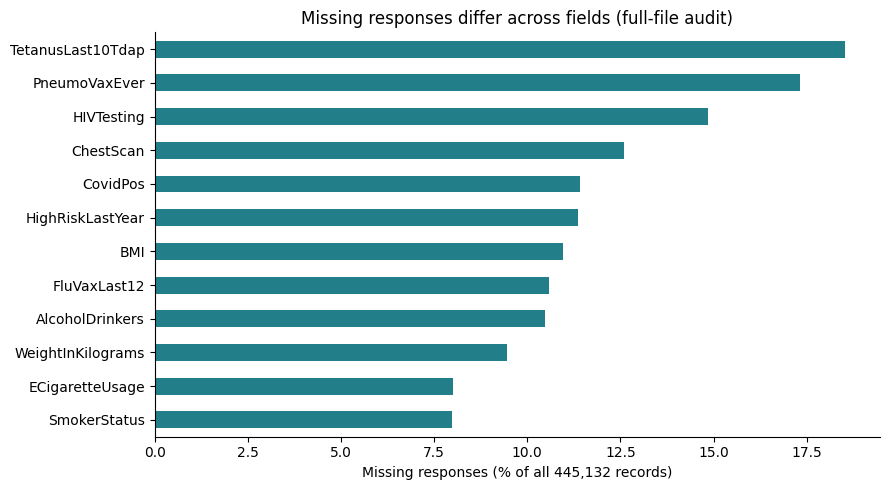

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
missing_summary.head(12).sort_values("missing_pct")["missing_pct"].plot.barh(ax=ax, color="#227f89")
ax.set_title("Missing responses differ across fields (full-file audit)")
ax.set_xlabel("Missing responses (% of all 445,132 records)")
ax.set_ylabel("")
ax.set_xlim(left=0)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Repeated rows and category checks
Identical responses do not prove the same person was surveyed twice. Keep records for now; Member 1 will keep identical records in the same split and document a sensitivity check.

In [15]:
duplicate_extra = int(df.duplicated().sum())
duplicate_all = int(df.duplicated(keep=False).sum())
display(pd.Series({"extra_identical_rows_after_first": duplicate_extra,
                   "all_rows_in_repeated_groups": duplicate_all,
                   "extra_identical_rows_pct": round(100 * duplicate_extra / len(df), 4)},
                  name="Duplicate audit"))

extra_identical_rows_after_first    157.0000
all_rows_in_repeated_groups         302.0000
extra_identical_rows_pct              0.0353
Name: Duplicate audit, dtype: float64

In [16]:
column_summary = pd.DataFrame({"dtype": df.dtypes.astype(str),
                               "unique_non_missing": df.nunique(dropna=True),
                               "missing_n": df.isna().sum()})
display(column_summary)

,dtype,unique_non_missing,missing_n
State,object,54,0
Sex,object,2,0
GeneralHealth,object,5,1198
PhysicalHealthDays,float64,31,10927
MentalHealthDays,float64,31,9067
LastCheckupTime,object,4,8308
PhysicalActivities,object,2,1093
SleepHours,float64,24,5453
RemovedTeeth,object,4,11360
HadHeartAttack,object,2,3065


In [18]:
# Inspect all string columns for formatting problems; do not silently change them.
text_checks = []
for col in df.select_dtypes(include="object"):
    s = df[col].dropna()
    text_checks.append({"column": col,
                        "blank_or_whitespace": int(s.str.strip().eq("").sum()),
                        "leading_or_trailing_spaces": int(s.ne(s.str.strip()).sum())})
display(pd.DataFrame(text_checks).set_index("column"))

,blank_or_whitespace,leading_or_trailing_spaces
column,,
State,0,0
Sex,0,0
GeneralHealth,0,0
LastCheckupTime,0,0
PhysicalActivities,0,0
RemovedTeeth,0,0
HadHeartAttack,0,0
HadAngina,0,0
HadStroke,0,0


## 7. Basic range flags
Days are checked against 0–30; sleep against 0–24. Non-positive body measurements are flagged. These are review checks, not clinical cut-offs or a complete validation of the CDC recoding. Plausible extreme observations stay in the raw data.

In [19]:
range_flags = {
    "PhysicalHealthDays_outside_0_30": df.PhysicalHealthDays.notna() & ~df.PhysicalHealthDays.between(0, 30),
    "MentalHealthDays_outside_0_30": df.MentalHealthDays.notna() & ~df.MentalHealthDays.between(0, 30),
    "SleepHours_outside_0_24": df.SleepHours.notna() & ~df.SleepHours.between(0, 24),
    "HeightInMeters_non_positive": df.HeightInMeters.le(0),
    "WeightInKilograms_non_positive": df.WeightInKilograms.le(0),
    "BMI_non_positive": df.BMI.le(0)
}
display(pd.Series({name: int(mask.sum()) for name, mask in range_flags.items()}, name="Flagged rows"))

PhysicalHealthDays_outside_0_30    0
MentalHealthDays_outside_0_30      0
SleepHours_outside_0_24            0
HeightInMeters_non_positive        0
WeightInKilograms_non_positive     0
BMI_non_positive                   0
Name: Flagged rows, dtype: int64

## 8. Audit the proposed target without changing `df`
`heart_disease` is our derived label; it is not a supplied column or a diagnosis made by this project.

* **1:** either `HadHeartAttack` or `HadAngina` is `Yes`, even if the other is missing.
* **0:** both are `No`.
* **Unknown:** neither is `Yes` and at least one is missing. Exclude these rows from modelling; do not impute their label.

Exclude both source columns from model inputs and Q2 associations. `HadStroke` stays a candidate predictor, as specified in the submitted proposal.

In [20]:
display(pd.crosstab(df["HadHeartAttack"].fillna("Missing"),
                    df["HadAngina"].fillna("Missing"), dropna=False))
for col in ["HadHeartAttack", "HadAngina"]:
    unexpected = set(df[col].dropna().unique()) - {"Yes", "No"}
    if unexpected:
        raise ValueError(f"Unexpected target codes in {col}: {unexpected}")

positive = df["HadHeartAttack"].eq("Yes") | df["HadAngina"].eq("Yes")
negative = df["HadHeartAttack"].eq("No") & df["HadAngina"].eq("No")
target = pd.Series(pd.NA, index=df.index, dtype="Int64", name="heart_disease")
target.loc[positive] = 1
target.loc[negative] = 0

target_audit = pd.DataFrame({"count": [int(positive.sum()), int(negative.sum()),
                                     int(target.isna().sum())]},
                          index=["Positive", "Negative", "Unknown"])
target_audit["pct_of_all_rows"] = target_audit["count"] / len(df) * 100
display(target_audit.round(2))
print(f"Known-target rows: {target.notna().sum():,}")
print(f"Positive proportion among known targets: {target.dropna().mean():.2%}")
print("Original dataframe is still:", df.shape)

Known-target rows: 440,111
Positive proportion among known targets: 9.03%
Original dataframe is still: (445132, 40)


HadAngina,Missing,No,Yes
HadHeartAttack,,,
Missing,817,1845,403
No,2359,400360,14240
Yes,1229,11971,11908


,count,pct_of_all_rows
Positive,39751,8.93
Negative,400360,89.94
Unknown,5021,1.13


## 9. What these checks tell us
The executed file has **445,132 rows and 40 original columns**. There are **157 extra identical rows** and **38 columns with missing values**. Tetanus vaccination has the largest missing count (82,516). The target rule produces **39,751 positives, 400,360 negatives and 5,021 unknown targets**. This is an imbalanced classification task.

Do not use `df.dropna()` across all columns: first quantify who would be lost and investigate why values are absent. Do not fit imputers or scalers on this full dataframe. Missingness and category audits alone do not establish MCAR/MAR/MNAR or causal effects.

## 10. What the team does next
1. Member 1 checks variable definitions and implements deterministic cleaning, the target and duplicate-aware 70/15/15 splits in `src/prepare_data.py`.
2. Save a reproducible split manifest locally under `data/processed/`. Freeze the row assignments. Keep generated CSVs out of Git.
3. Member 2 starts detailed EDA on training rows and prepares Q2 functions. Member 3 fits training-only pipelines and compares the baseline, logistic regression and random forest.
4. Member 3 returns validation predictor rankings. Member 2 uses those to complete the associated-factor analysis. Keep the test set untouched until all choices are frozen.
5. Write your own short interpretation of the checks below. Use the team task-plan PDF for exact deliverables and handoffs.

### Team notes to fill in after reviewing
* Which variable definitions or recodings need clarification?
* Which missingness patterns should we investigate on training data?
* Which unusual values need documentation checks?
* Which decisions could change who remains in our analysis?

